# Task 2: Imitation Learning

## Setup Code / Packages
This notebook runs locally in the `mujoco_cpu` conda environment (see `../docs/setup.md`), plus `pip install torch "imageio[ffmpeg]" moviepy==1.0.3`.

> **Why not Colab / mplib?** The template's expert uses the `mplib` motion planner, which isn't available for Apple Silicon or Python 3.13 (Colab's current version). The expert below is an inverse-kinematics (IK) controller written with MuJoCo, so everything runs locally.


In [1]:
import os, sys

# Paths: this notebook lives in task2/, the repo root is one level up.
SIM_ROOT = os.path.abspath("..")
if sys.platform.startswith("linux"):
    os.environ.setdefault("MUJOCO_GL", "egl")   # headless rendering on Linux servers
print("SIM_ROOT =", SIM_ROOT)


SIM_ROOT = /Users/harshatha/tritondroid_onboarding/simulation


In [2]:
import mujoco
_m = mujoco.MjModel.from_xml_path(os.path.join(SIM_ROOT, "assets/descriptions/DropCubeInBinEnv.xml"))
print(f"scene loads: nq={_m.nq} nv={_m.nv} nu={_m.nu} keyframes={_m.nkey}")
assert (_m.nq, _m.nu, _m.nkey) == (16, 8, 1), "Complete Task 1 first"


scene loads: nq=16 nv=15 nu=8 keyframes=1


## Using Gymnasium
No problems are assigned here, but understanding the code APIs/interfaces and functionalities are important.

### Gymnasium Basics
The Gymnasium package is a standardized API for creating and interacting with simulation environments. 

<img src="../assets/media/gym_loop.png" alt="agent-environment loop" width="500"/>

Gymnasium defines the agent-environment loop — a simple interface where an agent takes actions and receives observations, rewards, and termination signals from an environment. This loop forms the foundation for reinforcement learning (RL) and allows us to easily manipulate the simulator.

**Why We Use Gymnasium**

Gymnasium acts as a common interface layer between learning algorithms and simulation environments. It provides:
- A uniform API (reset(), step(), observation, reward, done, info) 
- Integration with RL algorithm libraries (e.g., Stable-Baselines3, CleanRL).
- Rendering and debugging utilities for visualization and evaluation.


In this task, you will use Gymnasium as the primary API to interface with the simulator to :
- Collect trajectory data for imitation learning.
- Evaluate and deploy trained policies.

Read their documentation [here](https://gymnasium.farama.org/).


## Part 0: Creating a Standardized Environment with Gymnasium
In this part, you will implement the `TrajEnv` class to wrap a MuJoCo simulation in a Gymnasium interface.

Your task is to decide which observations are useful as states in a behavior cloning setting. You will also implement the `is_grasped` property to define when the robot has successfully grasped the object and the `terminated` property to specify when the cube is in the bin. The `reset_model` method should randomize initial arm and object positions to encourage generalization.

You should step through Gymnasium functions like `do_simulation` and `set_state` to see how to control the simulator.

In [3]:
from gymnasium.envs.mujoco import MujocoEnv
from gymnasium.spaces import Box
import numpy as np
import mujoco
import os

XML_PATH = os.path.join(SIM_ROOT, "assets/descriptions/DropCubeInBinEnv.xml")

# Bin geometry (from bin_body.xml): inner walls at +-0.045 m, wall tops 0.055 m above the bin origin
BIN_INNER_HALF = 0.045
BIN_WALL_TOP = 0.055
CUBE_HALF = 0.02


def _safe_body_id(model: mujoco.MjModel, body_name: str):
    body_id = mujoco.mj_name2id(model, mujoco.mjtObj.mjOBJ_BODY, body_name)
    return body_id if body_id >= 0 else None


class TrajEnv(MujocoEnv):
    metadata = {"render_modes": ["human", "rgb_array", "depth_array"]}

    def __init__(self, xml_file: str, frame_skip: int = 5, cube_xy_range: float = 0.05, **kwargs):
        # Observation: [qpos, qvel] (16 + 15) plus task features (9):
        #   hand (TCP) position, cube minus hand, bin minus cube.
        # The relative vectors tell the policy directly "how far is the hand from the cube",
        # instead of making it work that out from joint angles.
        tmp_model = mujoco.MjModel.from_xml_path(xml_file)
        obs_dim = tmp_model.nq + tmp_model.nv + 9
        observation_space = Box(low=-np.inf, high=np.inf, shape=(obs_dim,), dtype=np.float32)

        super().__init__(xml_file, frame_skip, observation_space=observation_space, **kwargs)

        self.cube_xy_range = cube_xy_range
        self.panda_id = _safe_body_id(self.model, "panda_arm")
        self.hand_tcp_id = _safe_body_id(self.model, "panda_hand_tcp")
        self.cube_id = _safe_body_id(self.model, "cube")
        self.bin_id = _safe_body_id(self.model, "bin")
        self.cube_geom_id = self.model.geom("cube_geom").id
        self.finger_body_ids = {self.model.body("left_finger").id, self.model.body("right_finger").id}
        self.home_key_id = self.model.key("home").id

    @property
    def is_grasped(self) -> bool:
        # Grasped = the cube is touching BOTH fingers (checked in MuJoCo's contact list).
        touching = set()
        for c in self.data.contact[: self.data.ncon]:
            if self.cube_geom_id in (c.geom1, c.geom2):
                other = c.geom2 if c.geom1 == self.cube_geom_id else c.geom1
                body = self.model.geom_bodyid[other]
                if body in self.finger_body_ids:
                    touching.add(body)
        return touching == self.finger_body_ids

    @property
    def terminated(self) -> bool:
        # Success = cube center inside the bin's inner walls, below the wall tops, and released.
        cube = self.data.xpos[self.cube_id]
        bin_pos = self.data.xpos[self.bin_id]
        inside_xy = np.all(np.abs(cube[:2] - bin_pos[:2]) < BIN_INNER_HALF)
        below_rim = cube[2] < bin_pos[2] + BIN_WALL_TOP
        return bool(inside_xy and below_rim and not self.is_grasped)

    def _get_obs(self) -> np.ndarray:
        tcp = self.data.xpos[self.hand_tcp_id]
        cube = self.data.xpos[self.cube_id]
        bin_pos = self.data.xpos[self.bin_id]
        return np.concatenate([self.data.qpos.ravel(), self.data.qvel.ravel(),
                               tcp, cube - tcp, bin_pos - cube]).astype(np.float32)

    def step(self, action: np.ndarray):
        self.do_simulation(action, self.frame_skip)
        obs = self._get_obs()
        terminated = self.terminated
        reward = float(terminated)  # sparse success signal, only used for diagnostics in BC

        if self.render_mode == "human":
            self.render()
        # truncated=False: the TimeLimit wrapper handles episode truncation.
        return obs, reward, terminated, False, {"is_grasped": self.is_grasped}

    def reset_model(self):
        home = self.model.key(self.home_key_id)
        qpos = home.qpos.copy()
        qvel = np.zeros(self.model.nv)

        # Randomize the cube's start position in a small square around its default spot.
        qpos[9:11] += self.np_random.uniform(-self.cube_xy_range, self.cube_xy_range, size=2)
        # Small noise on the arm joints so the policy sees slightly different starts.
        qpos[:7] += self.np_random.uniform(-0.02, 0.02, size=7)

        self.set_state(qpos, qvel)
        # Hold the starting pose: position actuators need matching targets (gripper open = 255).
        self.data.ctrl[:] = np.concatenate([qpos[:7], [255.0]])
        return self._get_obs()


To understand what is happening in the environment, you can call `env.render()` to visualize it.  
Since we set `render_mode="rgb_array"`, `env.render()` will return an RGB array that can be displayed.  


> **Note:** If the default view of the environment is not ideal, you may need to adjust the camera.  
> You can do this by defining a camera in your Mujoco XML file and then passing its name as a kwarg to the `TrajEnv` constructor via the `camera_name` argument.


If you are on colab you can render the environment like so. If you are running MuJoCo locally you can use `render_mode="human"` to display viewing window.


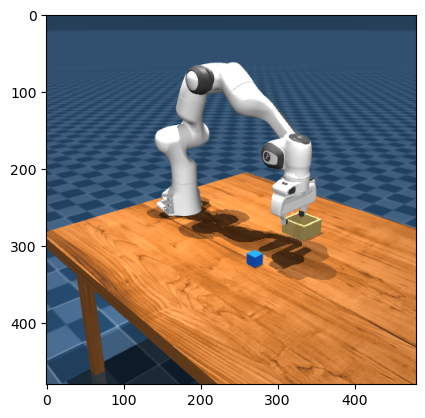

In [4]:
from gymnasium.wrappers import TimeLimit
import matplotlib.pyplot as plt

env = TrajEnv(XML_PATH, 20, render_mode='rgb_array', camera_name="fixed")
env = TimeLimit(env, 100)
env.reset()
image = env.render() 
image = image
plt.imshow(image)

With these core functionalities we can build the basic interaction loop that consists of a reset followed by steps until terminated or truncated is True. We can also record a video as well.

In [5]:
obs, _ = env.reset()
done = False
images = [env.render()]
# keep taking steps until either we terminated or truncate
while not done:
    obs, reward, terminated, truncated, info = env.step(env.action_space.sample())
    images.append(env.render())
    done = terminated or truncated

In [6]:
from IPython.display import Video
import imageio

frames = images 
frames = [frame.astype(np.uint8) for frame in frames]   

# Write video to file
video_path = "output_video.mp4"
with imageio.get_writer(video_path, fps=20) as writer:
    for frame in frames:
        writer.append_data(frame)

# Display video in notebook
Video(video_path, embed=True)

We will now control the robot to grasp the cube, pick it up, and drop it in the wooden bin.

**Expert: an inverse-kinematics (IK) controller instead of `mplib`.** IK answers *"which 7 joint angles put the hand at this position and orientation?"*. We solve it with **damped least squares** on MuJoCo's **Jacobian** (the matrix that says how the hand moves when each joint turns slightly), repeating small corrections until the hand is on target.

To move the hand from A to B, the expert splits the straight line into small steps (one per 0.02 s environment step) and solves IK for each one. The resulting joint angles are sent directly as actions, because the arm's actuators are position controllers. The gripper command is appended as the 8th action value (0 = closed, 255 = open).

- `panda_hand_tcp`: the "tool center point" between the fingertips; this is the point we steer.
- `cube`, `bin`: bodies whose positions we read from `env.data.xpos`.


In [7]:
import numpy as np
import mujoco

GRIPPER_OPEN, GRIPPER_CLOSED = 255.0, 0.0


class IKExpert:
    """Scripted pick-and-place expert built on inverse kinematics (IK).

    IK answers: "which 7 joint angles put the hand at this position and orientation?"
    We solve it with damped least squares on MuJoCo's Jacobian (the matrix that says how
    the hand moves when each joint turns a little), iterating until the hand is on target.
    """

    def __init__(self, model: mujoco.MjModel, tcp_body: str = "panda_hand_tcp"):
        self.model = model
        self.ik_data = mujoco.MjData(model)          # scratch copy: IK never touches the real sim
        self.tcp_id = model.body(tcp_body).id
        self.arm_dofs = np.arange(7)
        self.lower = model.jnt_range[:7, 0]
        self.upper = model.jnt_range[:7, 1]
        self.jacp = np.zeros((3, model.nv))
        self.jacr = np.zeros((3, model.nv))

    def solve_ik(self, q_init, target_pos, target_quat, iters=100, tol=1e-4, damping=1e-3):
        d = self.ik_data
        d.qpos[:] = 0
        d.qpos[:7] = q_init
        q = np.array(q_init, dtype=float)
        for _ in range(iters):
            d.qpos[:7] = q
            mujoco.mj_kinematics(self.model, d)
            mujoco.mj_comPos(self.model, d)
            pos_err = target_pos - d.xpos[self.tcp_id]
            rot_err_local = np.zeros(3)
            mujoco.mju_subQuat(rot_err_local, target_quat, d.xquat[self.tcp_id])
            rot_err = d.xmat[self.tcp_id].reshape(3, 3) @ rot_err_local  # hand frame -> world frame
            err = np.concatenate([pos_err, rot_err])
            if np.linalg.norm(err) < tol:
                break
            mujoco.mj_jacBody(self.model, d, self.jacp, self.jacr, self.tcp_id)
            J = np.vstack([self.jacp, self.jacr])[:, self.arm_dofs]
            dq = J.T @ np.linalg.solve(J @ J.T + damping * np.eye(6), err)
            q = np.clip(q + dq, self.lower, self.upper)
        return q, float(np.linalg.norm(err))

    def straight_line(self, q_start, start_pos, end_pos, quat, speed=0.25, dt=0.02):
        """Joint-angle waypoints that move the hand along a straight line (one per env step)."""
        n = max(int(np.ceil(np.linalg.norm(end_pos - start_pos) / (speed * dt))), 1)
        waypoints, q = [], q_start
        for s in np.linspace(0, 1, n + 1)[1:]:
            q, err = self.solve_ik(q, start_pos + s * (end_pos - start_pos), quat)
            if err > 1e-2:
                return None  # target unreachable
            waypoints.append(q)
        return waypoints


**Notes for this task**

The expert runs six phases, each a straight-line hand motion (or a pause), recording `(observation, action)` at every step:
1. move ~12 cm above the cube, gripper open
2. descend to the cube
3. close the gripper and hold for 0.5 s to squeeze
4. lift 15 cm
5. move above the bin
6. open the gripper and wait for the cube to drop

The hand keeps the same downward-pointing orientation throughout, so every grasp looks the same (this makes the demonstrations consistent, which helps imitation). The grasp is 1 cm above the cube's center so the fingertips stay off the table.


In [8]:
from gymnasium.wrappers import RecordVideo, TimeLimit

EPISODES = 10

env = TimeLimit(TrajEnv(xml_file=XML_PATH, frame_skip=20, render_mode="rgb_array", camera_name="fixed"), 500)
env = RecordVideo(
    env,
    "videos",                         # folder to save videos
    episode_trigger=lambda e: True,    # record every episode
    name_prefix="planner"
)


def pick_cube_solution(env, episode_data=None, expert=None, action_noise=0.0, rng=None):
    """Expert policy: approach -> descend -> close gripper -> lift -> move over bin -> release.

    Every env step it records (observation, action) into episode_data. Returns True on success.
    action_noise > 0 (DART): the robot executes a jittered action but the CLEAN expert action is
    recorded, so the dataset shows how to recover from small mistakes.
    """
    rng = rng if rng is not None else np.random.default_rng()
    base = env.unwrapped
    if expert is None:
        expert = IKExpert(base.model)
    dt = base.dt
    obs = base._get_obs()

    # Keep the hand pointing straight down, as at the home pose, for every phase.
    grasp_quat = base.data.xquat[base.hand_tcp_id].copy()
    cube = base.data.xpos[base.cube_id].copy()
    bin_pos = base.data.xpos[base.bin_id].copy()

    def run(actions):
        nonlocal obs
        for a in actions:
            if episode_data is not None:
                episode_data.append((obs.copy(), a.copy()))
            executed = a.copy()
            if action_noise > 0:
                executed[:7] += rng.normal(0, action_noise, size=7)
            obs, _, terminated, truncated, _ = env.step(executed)
            if truncated:
                return False
        return True

    def move_to(target, gripper, speed=0.25):
        q_now = base.data.qpos[:7].copy()
        path = expert.straight_line(q_now, base.data.xpos[base.hand_tcp_id].copy(), target, grasp_quat, speed, dt)
        if path is None:
            return False
        return run([np.append(q, gripper) for q in path])

    def hold(gripper, steps):
        q_hold = base.data.ctrl[:7].copy()
        return run([np.append(q_hold, gripper)] * steps)

    above_cube = cube + [0, 0, 0.12]
    at_cube = cube + [0, 0, 0.01]     # grasp 1 cm above the cube center: keeps the fingertips off the table
    lifted = cube + [0, 0, 0.15]
    above_bin = np.array([bin_pos[0], bin_pos[1], cube[2] + 0.15])

    ok = (move_to(above_cube, GRIPPER_OPEN)
          and move_to(at_cube, GRIPPER_OPEN, speed=0.15)
          and hold(GRIPPER_CLOSED, 25)            # squeeze
          and move_to(lifted, GRIPPER_CLOSED, speed=0.15)
          and move_to(above_bin, GRIPPER_CLOSED)
          and hold(GRIPPER_OPEN, 30))             # release and let the cube fall in
    return bool(ok and base.terminated)


expert = IKExpert(env.unwrapped.model)
successes = 0
for i in range(EPISODES):
    env.reset(seed=i)
    success = pick_cube_solution(env, expert=expert)
    successes += success

print(f"Expert success rate: {successes / EPISODES}")
env.close()


Expert success rate: 1.0


In [9]:
from IPython.display import Video
Video("videos/planner-episode-0.mp4", embed=True, width=320) # Watch replay

## Part 1: Collect your Imitation Learning Dataset


Now that you’ve used the motion planner to complete a single pick-and-place sequence, the next step is to repeat this process many times to collect a dataset for imitation learning.

In imitation learning, the dataset is made of trajectories—sequences of state-action pairs showing how an expert (in this case, the motion planner) solves the task. Each trajectory will later be used to train a policy that imitates this behavior.

>**Tip**: Standardizing the orientation and approach of the gripper will help the robot pick up the cube in the same way each time, resulting in a more reliable model.


In [10]:
import pickle
import time

env = TrajEnv(
    xml_file=XML_PATH,
    frame_skip=20,
)
expert = IKExpert(env.model)

trajectories = []

EPISODES = 300   # template: 10_000. 300 demos (~250 succeed with noise, ~63k pairs) takes ~1-2 min
success_count = 0
t0 = time.time()

for i in range(EPISODES):
    env.reset(seed=10_000 + i)   # different seeds from the demo/eval episodes
    episode_data = []

    # DART: the robot executes slightly noisy actions while the CLEAN expert action is recorded,
    # so the dataset also shows how to get back on track after small mistakes.
    result = pick_cube_solution(env, episode_data, expert, action_noise=0.02, rng=np.random.default_rng(i))

    if result:
        trajectories.append(episode_data)
        success_count += 1

# ===== Save dataset =====
with open("pick_place_dataset.pkl", "wb") as f:
    pickle.dump(trajectories, f)

print(f"Expert success rate with noise: {success_count / EPISODES}")
print(f"Total trajectories: {len(trajectories)} | steps per trajectory: "
      f"{min(map(len, trajectories))}-{max(map(len, trajectories))} | {time.time() - t0:.0f}s")
env.close()


Expert success rate with noise: 0.87
Total trajectories: 261 | steps per trajectory: 222-278 | 71s


## Part 2: Create Behavior Cloning Dataset

Using the trajectory data you have collected in the previous task, complete the `TrajectoryDataset` class to feed your model. 

>**NOTE**: The model learns to map states to actions, so the order of the data is not important. You can flatten all episodes and sample from any step freely.

In [11]:
from torch.utils.data import Dataset
import numpy as np
import pickle
import torch


class TrajectoryDataset(Dataset):
    def __init__(self, data):
        # data: list of episodes, each a list of (obs, action) pairs.
        # BC treats every pair as an independent example, so flatten all episodes together.
        pairs = [pair for episode in data for pair in episode]
        if not pairs:
            raise ValueError("Dataset is empty: collect some successful expert episodes first.")
        self.obs = torch.as_tensor(np.stack([o for o, _ in pairs]), dtype=torch.float32)
        self.actions = torch.as_tensor(np.stack([a for _, a in pairs]), dtype=torch.float32)

    def __len__(self):
        return len(self.obs)

    def __getitem__(self, idx):
        return self.obs[idx], self.actions[idx]


dataset_file = "pick_place_dataset.pkl"
with open(dataset_file, "rb") as f:
    data = pickle.load(f)
dataset = TrajectoryDataset(data)
print(f"{len(data)} episodes -> {len(dataset)} (obs, action) pairs | obs {tuple(dataset.obs.shape[1:])} action {tuple(dataset.actions.shape[1:])}")


261 episodes -> 65541 (obs, action) pairs | obs (40,) action (8,)


## Part 3: Define the Policy Network

In this step, you will implement a behavior cloning policy network. The goal of this network is to learn to map observations (states) to actions by imitating the trajectories you collected earlier. 

**NOTE**: See [tips](tips.md) for guidance on designing your network architecture and BC overview.

In [12]:
import torch
import torch.nn as nn


class Actor(nn.Module):
    """Gaussian policy: observation -> (mean action, log standard deviation).

    - Joint actions are predicted as a CHANGE from the current joint angles (obs[:7]): the expert's
      next target is always "current angle + a small step", and learning the small step is much
      more precise than learning the whole angle. The output is converted back to absolute targets.
    - Inputs and outputs are normalized internally (joint changes are ~0.01 rad but the gripper
      command is 0-255), so the network learns on comparable scales. The normalization stats are
      buffers, so they are saved and loaded with the checkpoint.
    """

    def __init__(self, obs_dim: int = 40, act_dim: int = 8, hidden: int = 256):
        super().__init__()
        self.trunk = nn.Sequential(
            nn.Linear(obs_dim, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
        )
        self.mean_head = nn.Linear(hidden, act_dim)
        self.log_std_head = nn.Linear(hidden, act_dim)
        self.register_buffer("obs_mean", torch.zeros(obs_dim))
        self.register_buffer("obs_std", torch.ones(obs_dim))
        self.register_buffer("act_mean", torch.zeros(act_dim))
        self.register_buffer("act_std", torch.ones(act_dim))

    def set_normalization(self, obs: torch.Tensor, actions: torch.Tensor):
        # Floor the std: near-constant inputs (e.g. the cube's rotation) would otherwise blow up.
        self.obs_mean.copy_(obs.mean(0)); self.obs_std.copy_(obs.std(0).clamp(min=1e-2))
        targets = self._to_delta(obs, actions)
        self.act_mean.copy_(targets.mean(0)); self.act_std.copy_(targets.std(0).clamp(min=1e-3))

    @staticmethod
    def _to_delta(obs, actions):
        delta = actions.clone()
        delta[..., :7] = actions[..., :7] - obs[..., :7]   # joint target minus current joint angle
        return delta

    def forward(self, x):
        h = self.trunk((x - self.obs_mean) / self.obs_std)
        mean_norm = self.mean_head(h)
        log_std_norm = self.log_std_head(h).clamp(-5, 2)   # keep the spread in a stable range
        # Map back to real action units, so the provided eval_policy and nll_loss work unchanged.
        mean = mean_norm * self.act_std + self.act_mean
        mean = torch.cat([mean[..., :7] + x[..., :7], mean[..., 7:]], dim=-1)   # delta -> absolute target
        log_std = log_std_norm + self.act_std.log()
        if not self.training:
            # The gripper is really a switch (0 = closed, 255 = open), but a Gaussian predicts
            # in-between values. At evaluation time, snap it to the nearest end.
            mean = mean.clone()
            mean[..., 7] = torch.where(mean[..., 7] > 127.5, 255.0, 0.0)
        return mean, log_std


## Part 4: Training Loop
You will train the neural network policy to imitate expert behavior.

We’ve provided an `eval_policy` function to test your actor in simulation. It runs several episodes and reports a success rate, so you can track how well your policy performs as training progresses.

In [13]:
import gymnasium as gym
import torch.nn as nn
import numpy as np
import torch

def eval_policy(eval_env: gym.Env, actor: nn.Module, num_episodes: int = 5):
    success = 0
    for ep in range(num_episodes):
        obs, _ = eval_env.reset()
        terminated, truncated = False, False
        
        while not (terminated or truncated):
            with torch.no_grad():
                action, _ = actor(torch.from_numpy(obs).float())
            obs, _, terminated, truncated, _ = eval_env.step(action.cpu().numpy())

        if terminated:
            success += 1
        
        print(f"Episode {ep+1}: Success={terminated}")
    return success / num_episodes

Episode 1: Success=False
Episode 2: Success=False
Episode 3: Success=False
Episode 4: Success=False
Episode 5: Success=False
epoch  10 | loss  -20.404 | eval success 0.00 | best 0.00 | 8s
Episode 1: Success=False
Episode 2: Success=False
Episode 3: Success=False
Episode 4: Success=False
Episode 5: Success=False
epoch  20 | loss  -21.406 | eval success 0.00 | best 0.00 | 16s
Episode 1: Success=False
Episode 2: Success=False
Episode 3: Success=False
Episode 4: Success=False
Episode 5: Success=False
epoch  30 | loss  -22.796 | eval success 0.00 | best 0.00 | 24s
Episode 1: Success=False
Episode 2: Success=False
Episode 3: Success=False
Episode 4: Success=False
Episode 5: Success=False
epoch  40 | loss  -22.988 | eval success 0.00 | best 0.00 | 32s
Episode 1: Success=False
Episode 2: Success=False
Episode 3: Success=False
Episode 4: Success=False
Episode 5: Success=False
epoch  50 | loss  -23.906 | eval success 0.00 | best 0.00 | 41s
Episode 1: Success=False
Episode 2: Success=False
Episod

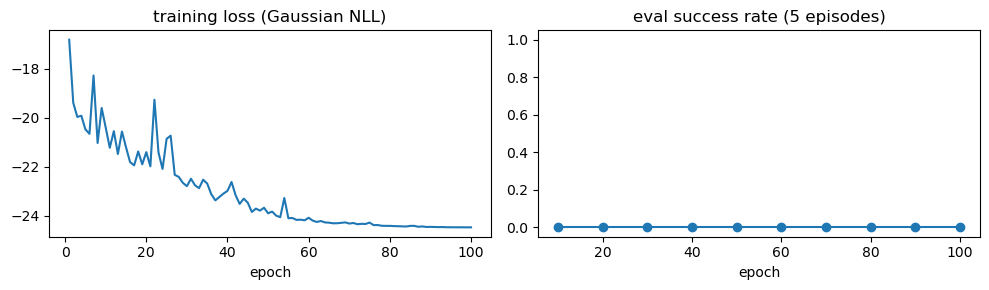

In [14]:
from torch.utils.data import DataLoader
from gymnasium.wrappers import TimeLimit
import numpy as np
import torch
import time

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

torch.manual_seed(0)
np.random.seed(0)

actor = Actor().to(device)
actor.set_normalization(dataset.obs.to(device), dataset.actions.to(device))
# TimeLimit added: without it eval_policy loops forever if the policy never succeeds.
eval_env = TimeLimit(TrajEnv(XML_PATH, 20), 400)

batch_size = 1024
dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=True)   # shuffled, as tips.md recommends

lr = 1e-3      # template: 3e-5, which barely moves in 100 epochs at this dataset size
epochs = 100
eval_every = 10

def nll_loss(actor: nn.Module, obs: torch.Tensor, expert_actions: torch.Tensor):
    mean, log_std = actor(obs)
    std = log_std.exp()
    dist = torch.distributions.Normal(mean, std)
    log_prob = dist.log_prob(expert_actions).sum(-1)   #sum over action dims
    loss = -log_prob.mean()
    return loss

optimizer = torch.optim.Adam(actor.parameters(), lr=lr)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
history = {"epoch": [], "loss": [], "eval_epoch": [], "success": []}
best_success, best_loss = -1.0, float("inf")
t0 = time.time()

for epoch in range(1, epochs + 1):
    actor.train()
    total, n = 0.0, 0
    for obs_b, act_b in dataloader:
        obs_b, act_b = obs_b.to(device), act_b.to(device)
        loss = nll_loss(actor, obs_b, act_b)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total += loss.item() * len(obs_b); n += len(obs_b)
    scheduler.step()
    epoch_loss = total / n
    history["epoch"].append(epoch); history["loss"].append(epoch_loss)

    if epoch % eval_every == 0 or epoch == epochs:
        actor.eval()
        success = eval_policy(eval_env, actor.cpu(), num_episodes=5)
        actor.to(device)
        history["eval_epoch"].append(epoch); history["success"].append(success)
        # Keep the checkpoint with the best success rate (lower loss breaks ties).
        if success > best_success or (success == best_success and epoch_loss < best_loss):
            best_success, best_loss = success, epoch_loss
            torch.save(actor.state_dict(), "best_policy.pth")
        print(f"epoch {epoch:3d} | loss {epoch_loss:8.3f} | eval success {success:.2f} | best {best_success:.2f} | {time.time() - t0:.0f}s")

print(f"Saved best_policy.pth (eval success {best_success:.2f}, loss {best_loss:.3f})")

import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].plot(history["epoch"], history["loss"]); ax[0].set_title("training loss (Gaussian NLL)"); ax[0].set_xlabel("epoch")
ax[1].plot(history["eval_epoch"], history["success"], marker="o"); ax[1].set_title("eval success rate (5 episodes)")
ax[1].set_xlabel("epoch"); ax[1].set_ylim(-0.05, 1.05)
plt.tight_layout(); plt.show()


## Part 5: Evaluate in Simulator
Time to evaluate your model. You may notice that it doesn’t succeed very often and may behave unpredictably or erratically. 

Can you think about why this might happen?

In [15]:
import torch
import numpy as np
from gymnasium.wrappers import RecordVideo, TimeLimit


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

torch.manual_seed(0)
np.random.seed(0)

# TimeLimit added so failed episodes end; camera_name added for the angled view
eval_env = TimeLimit(TrajEnv(XML_PATH, 20, render_mode='rgb_array', camera_name='fixed'), 400)
eval_env = RecordVideo(
    eval_env,
    "videos",                       # folder to save videos
    episode_trigger=lambda e: True,  # record every episode
    name_prefix="bc-model"
    )
actor = Actor().to(device)

state_dict = torch.load('best_policy.pth')
actor.load_state_dict(state_dict)
actor.eval()   # evaluation mode (also snaps the gripper to open/closed)

#Evaluation
eval_success = eval_policy(eval_env, actor, 10)
print(f"BC policy success rate: {eval_success:.2f}")
eval_env.close()

/Users/harshatha/miniforge3/envs/mujoco_cpu/lib/python3.11/site-packages/gymnasium/wrappers/record_video.py:94: UserWarning: WARN: Overwriting existing videos at /Users/harshatha/tritondroid_onboarding/simulation/task2/videos folder (try specifying a different `video_folder` for the `RecordVideo` wrapper if this is not desired)
  logger.warn(


Episode 1: Success=False
Episode 2: Success=False
Episode 3: Success=False
Episode 4: Success=False
Episode 5: Success=False
Episode 6: Success=False
Episode 7: Success=False
Episode 8: Success=False
Episode 9: Success=False
Episode 10: Success=False
BC policy success rate: 0.00


In [16]:
from IPython.display import Video
Video("videos/bc-model-episode-0.mp4", embed=True, width=320) # Watch our replay

## Results

| Stage | Result |
|---|---|
| IK expert (no noise) | **10/10** successful pick-and-place (`videos/planner-episode-*.mp4`) |
| Expert with DART noise (0.02 rad) | 87% success → **261 demonstrations, 65,541 (obs, action) pairs** |
| BC policy (100 epochs, Gaussian NLL) | **0/10** success (`videos/bc-model-episode-*.mp4`) |

**What the BC policy does:** it moves the hand to the cube accurately (within ~0.5 cm) and closes the gripper on it in most episodes, but it doesn't lift the cube. While gripping, the hand drifts ~2 cm sideways, so the fingers slide off and the cube gets pushed around the table.

### Changes tried, and what each one fixed
Development runs (300 demos, 100 epochs each), measured over 5 evaluation rollouts per version:

| Version | Change | Closest hand-to-cube distance | Grasped the cube |
|---|---|---|---|
| v1 | obs = joint angles + velocities (31 numbers) | 1.6–5.4 cm | 1/5 |
| v2 | + hand position, hand→cube and cube→bin vectors; gripper snapped to open/closed at eval | 3.4–9.5 cm | 2/5 |
| v3 | + predict joint *changes* (delta actions) + **DART** noise-injected demos | **0.3–0.6 cm** | 1/5 |
| v4 (this notebook) | + grasp 1 cm higher so the fingertips don't jam on the table | 0.6–0.8 cm | **5/5** |
| v5 (reverted) | + the policy's own last command and a "steps since gripper closed" counter | 0.5–0.8 cm | 0/5, and the arm runs away |

### BC limitations observed

1. **Covariate shift (compounding errors).** BC trains only on states the expert visited. In v1/v2 the policy drifted a few centimetres off the expert's path early on and, never having seen those states, couldn't correct, so errors snowballed (in one rollout the arm ended up 1.6 m in the air). **DART** (noisy demonstrations labelled with the clean expert action) adds "how to recover" examples and cut the reaching error from ~4 cm to ~0.5 cm, which is direct evidence that covariate shift was the problem.
2. **The expert has a hidden clock; the policy doesn't.** The scripted expert switches phases on a timer: "hold the gripper closed for 25 steps, *then* lift". The policy only sees the current state, and "hand at the cube, fingers closing" looks almost the same whether the expert was about to keep squeezing or start lifting. BC fits the average of those actions, which produces the hesitating, drifting grasp in the videos. Fixes would be giving the policy history (a few past observations) or phase information, predicting short action sequences instead of single steps (action chunking), or collecting corrective labels on the policy's own states (DAgger).
3. **Causal confusion ("copycat" problem), seen in v5.** Giving the policy its own previous command made it worse: in expert data consecutive actions are nearly identical, so the easiest thing to learn is "repeat the last command" instead of reacting to the cube. At test time one wrong command feeds into the next and the arm runs away (~1.3 m off). This is a known BC failure (de Haan et al., 2019, *Causal Confusion in Imitation Learning*), so v5 was reverted.
